# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Jordan Sebastian Simatupang | 5054251038 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100

In [2]:
df = pd.read_csv("Live.csv")
print("Ukuran dataset (baris, kolom):", df.shape)
print("\nInformasi tipe data dan non-null:")
df.info()

print("\nJumlah missing value per kolom:")
print(df.isnull().sum())

print("\nJumlah baris duplikat persis:", df.duplicated().sum())
print("Jumlah baris duplikat (tanpa status_id):", df.drop(columns=["status_id"]).duplicated().sum())

print("\nStatistik deskriptif fitur numerik:")
display(df.describe().T)

Ukuran dataset (baris, kolom): (7050, 16)

Informasi tipe data dan non-null:
<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non

,count,mean,std,min,25%,50%,75%,max
status_id,7050.0,3525.500000,2035.304031,1.0,1763.25,3525.5,5287.75,7050.0
num_reactions,7050.0,230.117163,462.625309,0.0,17.00,59.5,219.00,4710.0
num_comments,7050.0,224.356028,889.636820,0.0,0.00,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.00,0.0,4.00,3424.0
num_likes,7050.0,215.043121,449.472357,0.0,17.00,58.0,184.75,4710.0
num_loves,7050.0,12.728652,39.972930,0.0,0.00,0.0,3.00,657.0
num_wows,7050.0,1.289362,8.719650,0.0,0.00,0.0,0.00,278.0
num_hahas,7050.0,0.696454,3.957183,0.0,0.00,0.0,0.00,157.0
num_sads,7050.0,0.243688,1.597156,0.0,0.00,0.0,0.00,51.0
num_angrys,7050.0,0.113191,0.726812,0.0,0.00,0.0,0.00,31.0


,skewness,proporsi_nol (%),median,max
num_reactions,3.74,1.72,59.5,4710
num_comments,9.03,30.06,4.0,20990
num_shares,7.10,55.48,0.0,3424
num_likes,3.92,1.79,58.0,4710
num_loves,6.00,60.00,0.0,657
num_wows,18.25,75.29,0.0,278
num_hahas,20.31,83.91,0.0,157
num_sads,17.58,91.39,0.0,51
num_angrys,19.51,94.00,0.0,31


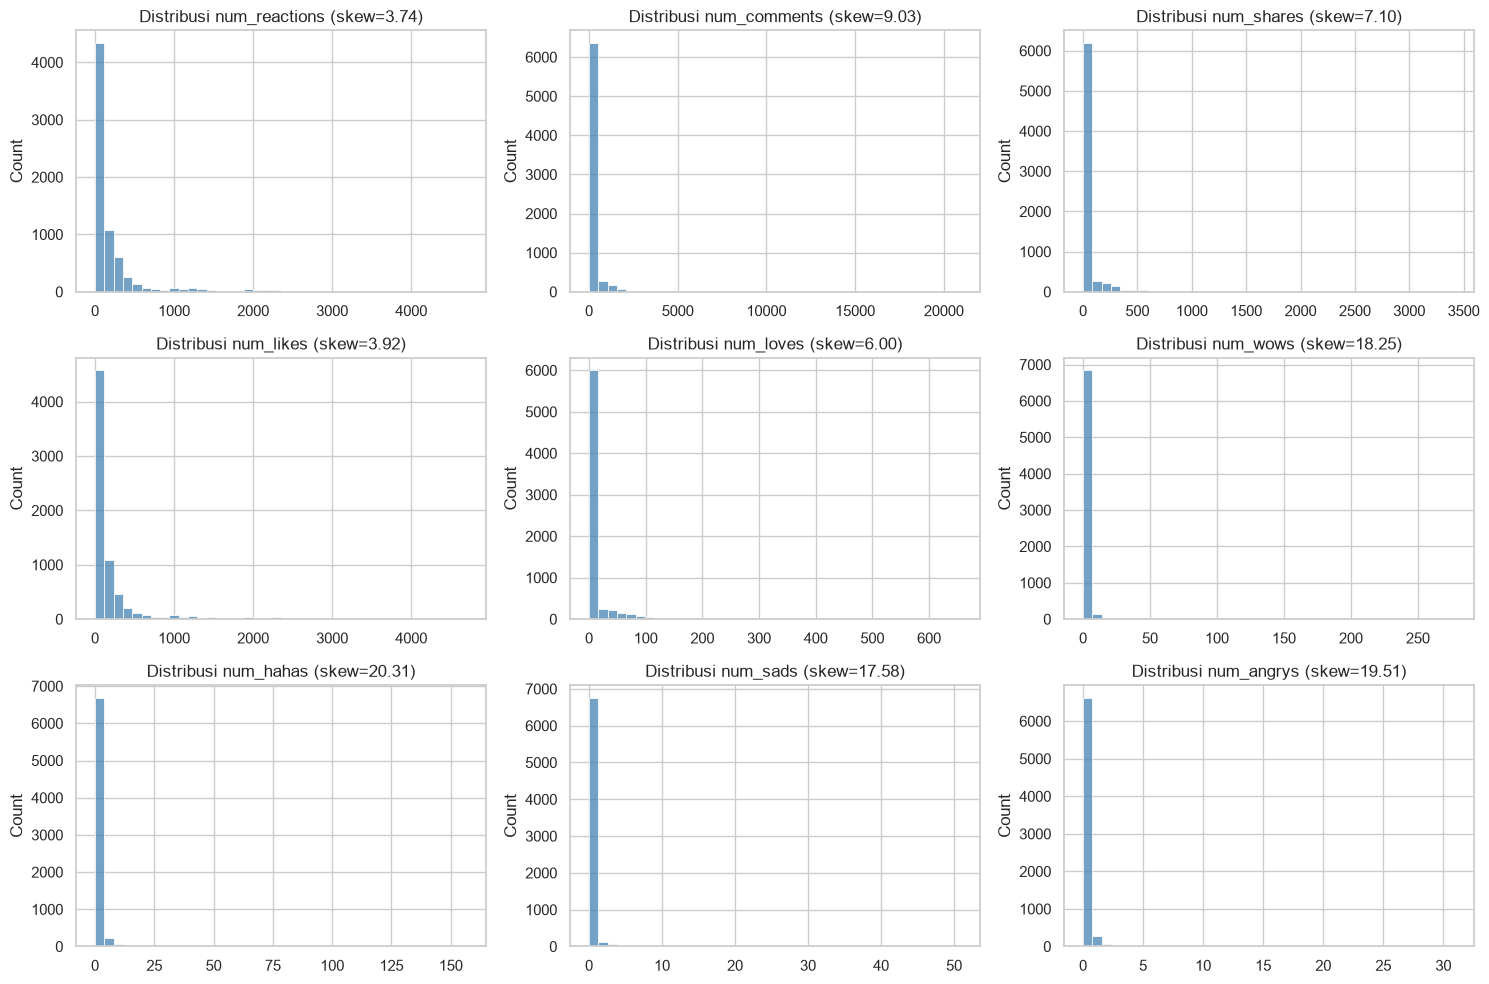

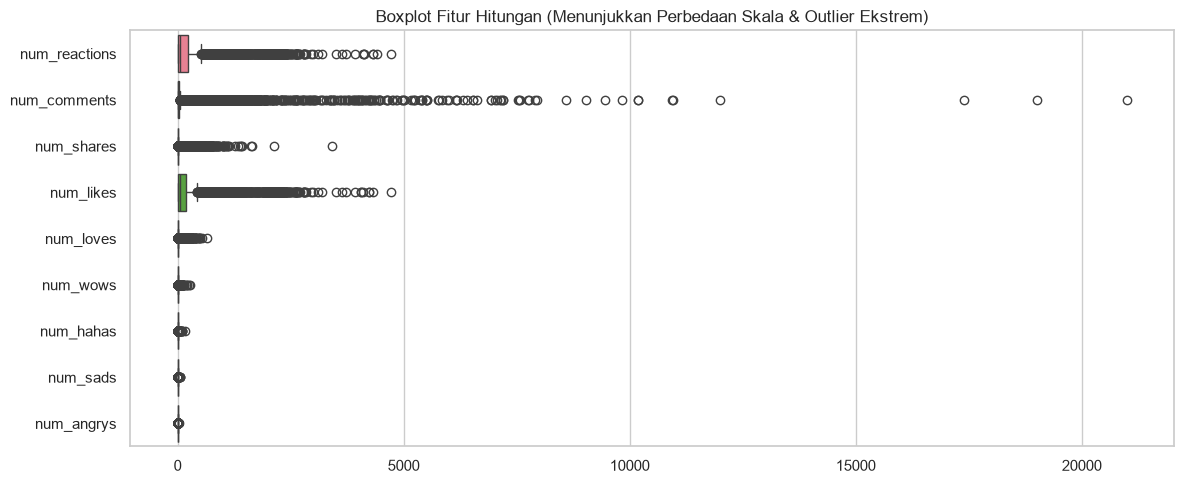

In [3]:
count_cols = [
    "num_reactions", "num_comments", "num_shares",
    "num_likes", "num_loves", "num_wows",
    "num_hahas", "num_sads", "num_angrys"
]

summary_dist = pd.DataFrame({
    "skewness": df[count_cols].skew(),
    "proporsi_nol (%)": (df[count_cols] == 0).mean() * 100,
    "median": df[count_cols].median(),
    "max": df[count_cols].max()
}).round(2)
display(summary_dist)

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.flatten(), count_cols):
    sns.histplot(df[col], bins=40, ax=ax, kde=False, color="steelblue")
    ax.set_title(f"Distribusi {col} (skew={df[col].skew():.2f})")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df[count_cols], orient="h", ax=ax)
ax.set_title("Boxplot Fitur Hitungan (Menunjukkan Perbedaan Skala & Outlier Ekstrem)")
plt.tight_layout()
plt.show()

Selisih maksimum |num_reactions - jumlah(likes + emoji)|: 4


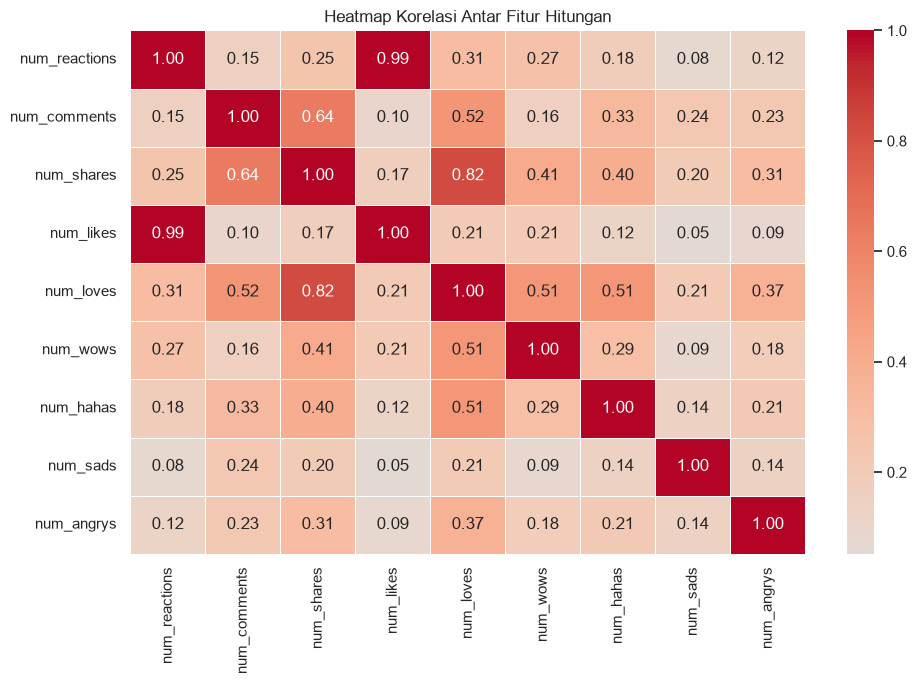

In [4]:
plt.figure(figsize=(10, 7))
corr_matrix = df[count_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Heatmap Korelasi Antar Fitur Hitungan")
plt.tight_layout()
plt.show()

diff_reactions = (df["num_reactions"] - df[["num_likes", "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]].sum(axis=1)).abs()
print("Selisih maksimum |num_reactions - jumlah(likes + emoji)|:", diff_reactions.max())

,year,jumlah_posting,proporsi_emoji (%)
0,2012,589,0.00
1,2013,500,0.00
2,2014,233,0.00
3,2015,337,0.00
4,2016,588,68.03
5,2017,2253,54.19
6,2018,2550,57.76


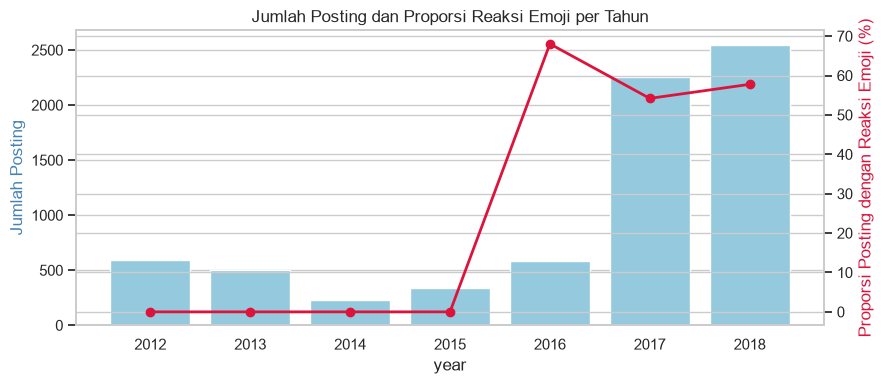

In [5]:
df["status_published"] = pd.to_datetime(df["status_published"])
df["year"] = df["status_published"].dt.year

emoji_cols = ["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
df["has_emoji"] = df[emoji_cols].sum(axis=1) > 0

yearly_stats = df.groupby("year").agg(
    jumlah_posting=("status_id", "count"),
    proporsi_emoji=("has_emoji", "mean")
).reset_index()
yearly_stats["proporsi_emoji (%)"] = (yearly_stats["proporsi_emoji"] * 100).round(2)
display(yearly_stats[["year", "jumlah_posting", "proporsi_emoji (%)"]])

fig, ax1 = plt.subplots(figsize=(9, 4))
sns.barplot(data=yearly_stats, x="year", y="jumlah_posting", color="skyblue", ax=ax1)
ax1.set_ylabel("Jumlah Posting", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(range(len(yearly_stats)), yearly_stats["proporsi_emoji (%)"], color="crimson", marker="o", linewidth=2, label="Proporsi Emoji (%)")
ax2.set_ylabel("Proporsi Posting dengan Reaksi Emoji (%)", color="crimson")
ax1.set_title("Jumlah Posting dan Proporsi Reaksi Emoji per Tahun")
plt.tight_layout()
plt.show()

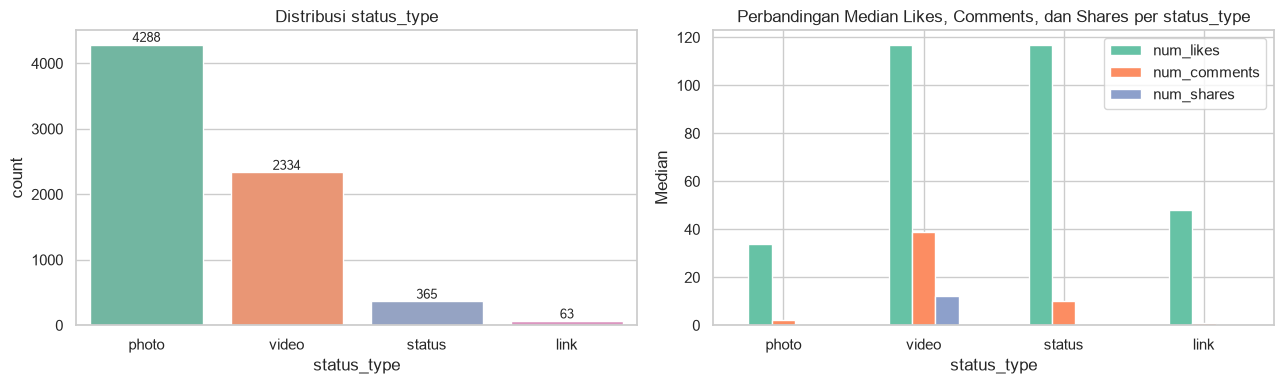

,num_likes,num_comments,num_shares
status_type,,,
photo,34.0,2.0,0.0
video,117.0,39.0,12.0
status,117.0,10.0,0.0
link,48.0,1.0,0.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

order_type = df["status_type"].value_counts().index
sns.countplot(data=df, x="status_type", order=order_type, ax=axes[0], palette="Set2")
axes[0].set_title("Distribusi status_type")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha="center", va="bottom", fontsize=9)

median_by_type = df.groupby("status_type")[["num_likes", "num_comments", "num_shares"]].median().loc[order_type]
median_by_type.plot(kind="bar", ax=axes[1])
axes[1].set_title("Perbandingan Median Likes, Comments, dan Shares per status_type")
axes[1].set_ylabel("Median")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()
display(median_by_type)

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [7]:
# 1. Hapus kolom yang seluruhnya kosong (Column1 - Column4)
empty_cols = [col for col in df.columns if df[col].isnull().all()]
print("Kolom kosong yang dihapus:", empty_cols)
df_clean = df.drop(columns=empty_cols + ["year", "has_emoji"], errors="ignore").copy()

# 2. Tangani baris duplikat (mengecualikan status_id karena selalu unik)
dup_count = df_clean.drop(columns=["status_id"]).duplicated().sum()
print("Jumlah duplikat (tanpa status_id) sebelum dihapus:", dup_count)
df_clean = df_clean.drop_duplicates(subset=[c for c in df_clean.columns if c != "status_id"]).reset_index(drop=True)
print("Ukuran dataset setelah deduplikasi:", df_clean.shape)

# 3. Periksa missing value tersisa
print("Total missing value tersisa:", df_clean.isnull().sum().sum())

# 4. Catatan outlier ekstrem:
# Outlier pada engagement (postingan viral) adalah fenomena nyata pada data media sosial,
# sehingga tidak dihapus melainkan dikompresi rentangnya menggunakan transformasi log1p.

Kolom kosong yang dihapus: ['Column1', 'Column2', 'Column3', 'Column4']
Jumlah duplikat (tanpa status_id) sebelum dihapus: 54
Ukuran dataset setelah deduplikasi: (6996, 12)
Total missing value tersisa: 0


In [8]:
# Pisahkan kolom metadata untuk interpretasi cluster pada tahap evaluasi
meta_df = df_clean[["status_type", "status_published"]].copy()

# Gabungkan fitur reaksi emoji yang sparse (60%-94% bernilai nol) menjadi satu fitur total num_emojis
emoji_cols = ["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
df_clean["num_emojis"] = df_clean[emoji_cols].sum(axis=1)

# Pilih fitur clustering (menghapus status_id dan num_reactions yang redundan)
selected_features = ["num_likes", "num_comments", "num_shares", "num_emojis"]
X_raw = df_clean[selected_features].copy()

print("Fitur terpilih:", selected_features)
print("Proporsi nilai nol pada fitur terpilih (%):")
print(((X_raw == 0).mean() * 100).round(2))
display(X_raw.describe().T)

Fitur terpilih: ['num_likes', 'num_comments', 'num_shares', 'num_emojis']
Proporsi nilai nol pada fitur terpilih (%):
num_likes        1.76
num_comments    30.25
num_shares      55.82
num_emojis      56.50
dtype: float64


,count,mean,std,min,25%,50%,75%,max
num_likes,6996.0,210.036735,439.623067,0.0,17.0,57.0,182.00,4710.0
num_comments,6996.0,225.648799,892.922206,0.0,0.0,4.0,22.25,20990.0
num_shares,6996.0,40.275872,132.072584,0.0,0.0,0.0,4.00,3424.0
num_emojis,6996.0,15.051601,47.953856,0.0,0.0,0.0,5.00,886.0


**Fitur yang dipilih untuk clustering:** `num_likes`, `num_comments`, `num_shares`, dan `num_emojis`.

**Alasan pemilihan dan penanganan fitur:**
1. **`status_id` dan `status_published` tidak dipakai sebagai fitur clustering:** `status_id` hanya merupakan identifier unik tiap baris, sedangkan `status_type` dan `status_published` dipisahkan untuk keperluan interpretasi dan evaluasi.
2. **`num_reactions` dihapus karena redundan:** Secara definisi `num_reactions` merupakan penjumlahan dari `num_likes` dan seluruh reaksi emoji (`num_loves`, `num_wows`, `num_hahas`, `num_sads`, `num_angrys`), dengan selisih maksimum hanya 4 pada dataset. Mempertahankan `num_reactions` bersamaan dengan komponennya akan menggandakan bobot informasi yang sama pada perhitungan jarak Euclidean.
3. **Lima fitur emoji digabung menjadi `num_emojis`:** Fitur `num_loves` (60,00% nol), `num_wows` (75,29% nol), `num_hahas` (83,91% nol), `num_sads` (91,39% nol), dan `num_angrys` (94,00% nol) sangat *sparse* dan baru muncul setelah Facebook meluncurkan fitur Reactions pada tahun 2016 (proporsi posting ber-emoji 0% pada 2012–2015, lalu melonjak menjadi 54%–68% pada 2016–2018). Menggabungkannya menjadi `num_emojis` menurunkan proporsi nilai nol menjadi 56,50% sekaligus menjaga sinyal ekspresi emosional tanpa membuat dimensi jarak didominasi kolom yang hampir seluruhnya nol.

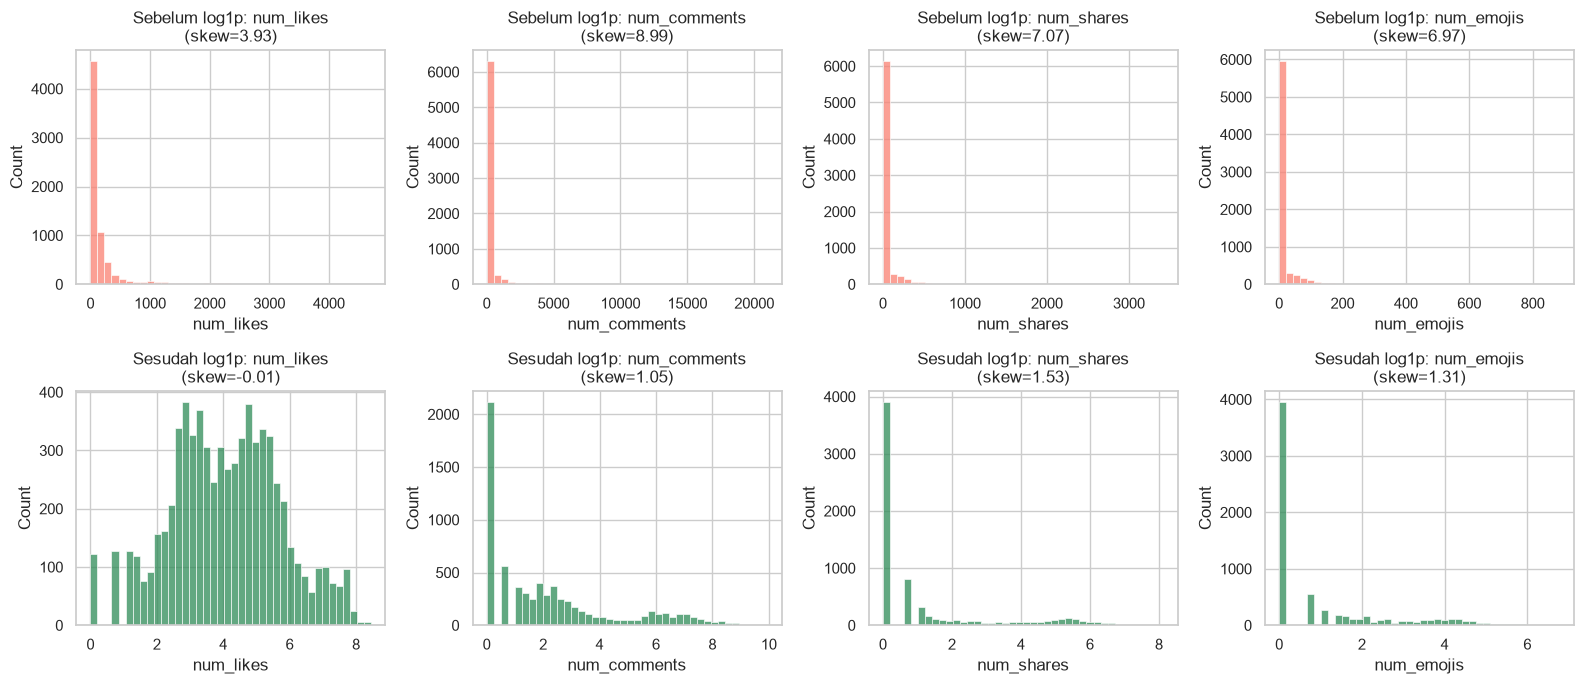

In [9]:
X_log = np.log1p(X_raw)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, col in enumerate(selected_features):
    sns.histplot(X_raw[col], bins=40, ax=axes[0, i], color="salmon")
    axes[0, i].set_title(f"Sebelum log1p: {col}\n(skew={X_raw[col].skew():.2f})")
    
    sns.histplot(X_log[col], bins=40, ax=axes[1, i], color="seagreen")
    axes[1, i].set_title(f"Sesudah log1p: {col}\n(skew={X_log[col].skew():.2f})")

plt.tight_layout()
plt.show()

In [10]:
scaler_raw = StandardScaler()
X_raw_scaled = pd.DataFrame(scaler_raw.fit_transform(X_raw), columns=selected_features)

scaler_log = StandardScaler()
X_log_scaled = pd.DataFrame(scaler_log.fit_transform(X_log), columns=selected_features)

print("Mean dan Std X_log_scaled:")
display(pd.DataFrame({"mean": X_log_scaled.mean().round(4), "std": X_log_scaled.std().round(4)}))

Mean dan Std X_log_scaled:


,mean,std
num_likes,-0.0,1.0001
num_comments,-0.0,1.0001
num_shares,0.0,1.0001
num_emojis,-0.0,1.0001


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [11]:
km_raw = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_raw)
km_raw_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_raw_scaled)
km_log_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_log_scaled)

In [12]:
print("Varians masing-masing fitur pada X_raw (tanpa scaling):")
print(X_raw.var().round(2).sort_values(ascending=False))

comparison_31 = []
for name, model in [
    ("X_raw (mentah)", km_raw),
    ("X_raw_scaled (scaling saja)", km_raw_scaled),
    ("X_log_scaled (log1p + scaling)", km_log_scaled),
]:
    counts = pd.Series(model.labels_).value_counts().sort_index().to_dict()
    sil = silhouette_score(X_log_scaled, model.labels_)
    comparison_31.append({
        "Representasi Data": name,
        "Silhouette Score (di X_log_scaled)": round(sil, 4),
        "Distribusi Anggota Cluster": str(counts)
    })

display(pd.DataFrame(comparison_31))

Varians masing-masing fitur pada X_raw (tanpa scaling):
num_comments    797310.07
num_likes       193268.44
num_shares       17443.17
num_emojis        2299.57
dtype: float64


,Representasi Data,Silhouette Score (di X_log_scaled),Distribusi Anggota Cluster
0,X_raw (mentah),0.2731,"{0: 6392, 1: 137, 2: 467}"
1,X_raw_scaled (scaling saja),0.2533,"{0: 373, 1: 6277, 2: 346}"
2,X_log_scaled (log1p + scaling),0.4638,"{0: 1131, 1: 2258, 2: 3607}"


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [13]:
k_range = range(2, 11)
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_log_scaled)
    inertias.append(km.inertia_)

elbow_df = pd.DataFrame({"k": list(k_range), "inertia": np.round(inertias, 2)})
elbow_df["penurunan_inertia"] = elbow_df["inertia"].diff().abs().round(2)
display(elbow_df)

,k,inertia,penurunan_inertia
0,2,11586.90,NaN
1,3,6779.84,4807.06
2,4,5678.25,1101.59
3,5,4739.96,938.29
4,6,4220.28,519.68
5,7,3772.10,448.18
6,8,3418.57,353.53
7,9,3116.43,302.14
8,10,2899.05,217.38


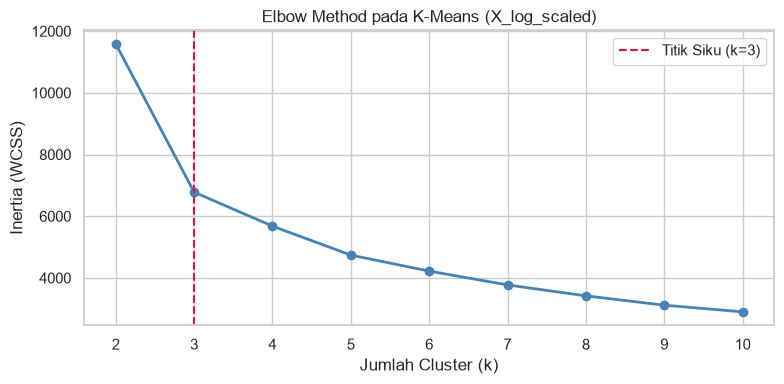

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(list(k_range), inertias, marker="o", linewidth=2, color="steelblue")
plt.axvline(x=3, color="crimson", linestyle="--", label="Titik Siku (k=3)")
plt.title("Elbow Method pada K-Means (X_log_scaled)")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(list(k_range))
plt.legend()
plt.tight_layout()
plt.show()

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [15]:
sil_scores = {}
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_log_scaled)
    sil_scores[k] = silhouette_score(X_log_scaled, labels)

sil_df = pd.DataFrame({"k": list(sil_scores.keys()), "silhouette_score": np.round(list(sil_scores.values()), 4)})
display(sil_df)

,k,silhouette_score
0,2,0.5899
1,3,0.4638
2,4,0.3372
3,5,0.3586
4,6,0.3469
5,7,0.3367
6,8,0.3154
7,9,0.3293
8,10,0.3160


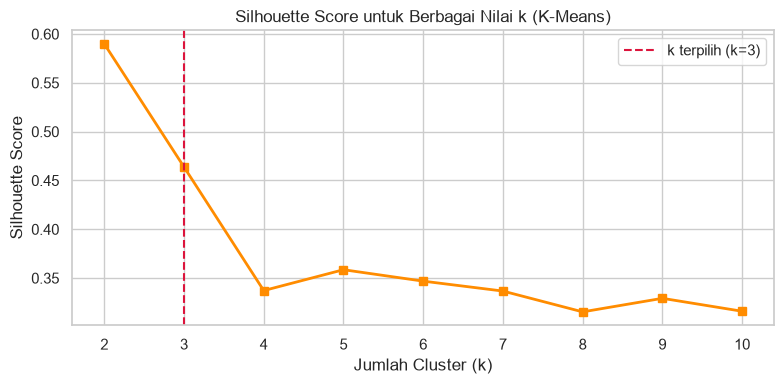

In [16]:
plt.figure(figsize=(8, 4))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker="s", linewidth=2, color="darkorange")
plt.axvline(x=3, color="crimson", linestyle="--", label="k terpilih (k=3)")
plt.title("Silhouette Score untuk Berbagai Nilai k (K-Means)")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_range))
plt.legend()
plt.tight_layout()
plt.show()

**Pilihan k untuk K-Means:** `k = 3`

**Alasan:**
- Pada grafik **Elbow Method**, penurunan *inertia* terbesar terjadi dari `k = 2` (11.586,90) ke `k = 3` (6.779,84) dengan penurunan sebesar **4.807,06**. Setelah `k = 3`, penurunan *inertia* melandai secara signifikan (hanya 1.101,59 ke `k = 4` dan 938,29 ke `k = 5`), sehingga titik siku (*elbow*) terbentuk jelas pada `k = 3`.
- Pada **Silhouette Score**, nilai tertinggi memang berada di `k = 2` (0,5899), namun `k = 3` masih mempertahankan skor yang baik (**0,4638**) sebelum turun tajam di `k = 4` (0,3372). Memilih `k = 3` memberikan segmentasi engagement yang lebih informatif (rendah, menengah berbasis like, dan tinggi berbasis diskusi/share video) dibandingkan hanya membagi dua kelompok ekstrem.

## 3.4 Model K-Means Final

In [17]:
best_k = 3
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
km_labels = kmeans_final.fit_predict(X_log_scaled)
print("Jumlah anggota tiap cluster (K-Means):")
print(pd.Series(km_labels).value_counts().sort_index())

Jumlah anggota tiap cluster (K-Means):
0    1131
1    2258
2    3607
Name: count, dtype: int64


In [18]:
profile_km = X_raw.copy()
profile_km["cluster"] = km_labels

km_counts = profile_km["cluster"].value_counts().sort_index().rename("jumlah_anggota")
km_medians = profile_km.groupby("cluster").median().round(2).add_suffix("_median")
km_means = profile_km.groupby("cluster").mean().round(2).add_suffix("_mean")

display(pd.concat([km_counts, km_medians, km_means], axis=1))

,jumlah_anggota,num_likes_median,num_comments_median,num_shares_median,num_emojis_median,num_likes_mean,num_comments_mean,num_shares_mean,num_emojis_mean
cluster,,,,,,,,,
0,1131,170.0,722.0,178.0,57.0,304.50,1335.37,238.04,83.25
1,2258,206.0,11.0,1.0,2.0,462.73,26.89,4.69,4.57
2,3607,18.0,0.0,0.0,0.0,22.23,2.11,0.55,0.23


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [19]:
Z_ward = linkage(X_log_scaled, method="ward")
print("Shape linkage matrix:", Z_ward.shape)

Shape linkage matrix: (6995, 4)


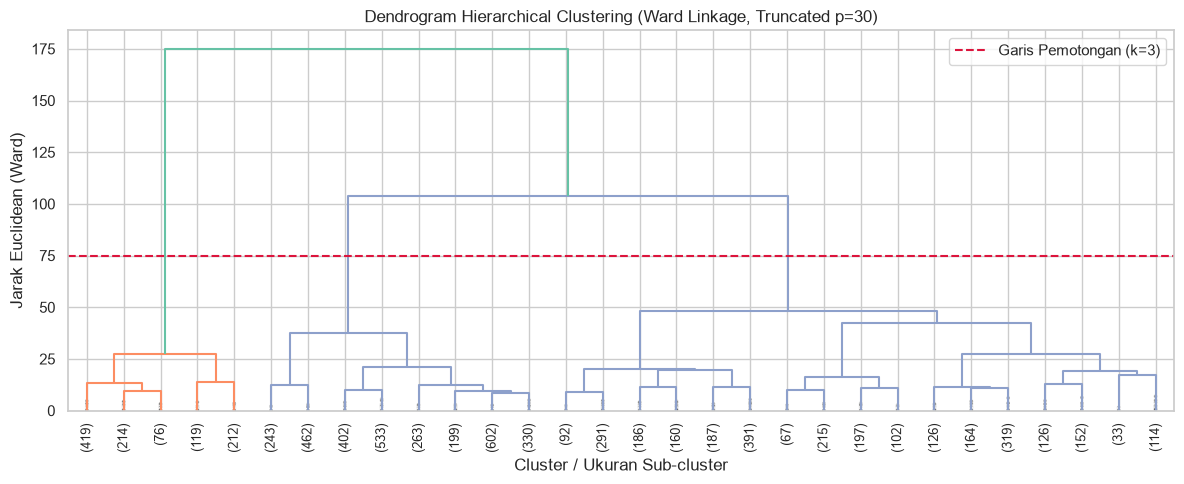

In [20]:
plt.figure(figsize=(12, 5))
dendrogram(
    Z_ward,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)
plt.axhline(y=75, color="crimson", linestyle="--", label="Garis Pemotongan (k=3)")
plt.title("Dendrogram Hierarchical Clustering (Ward Linkage, Truncated p=30)")
plt.xlabel("Cluster / Ukuran Sub-cluster")
plt.ylabel("Jarak Euclidean (Ward)")
plt.legend()
plt.tight_layout()
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [21]:
linkages = ["ward", "complete", "average", "single"]
hc_models = {}
hc_labels_dict = {}

for link in linkages:
    model = AgglomerativeClustering(n_clusters=best_k, linkage=link)
    hc_labels_dict[link] = model.fit_predict(X_log_scaled)
    hc_models[link] = model

In [22]:
linkage_results = []
for link in linkages:
    labels = hc_labels_dict[link]
    sil = silhouette_score(X_log_scaled, labels)
    counts = pd.Series(labels).value_counts().sort_index().to_dict()
    linkage_results.append({
        "Metode Linkage": link,
        "Silhouette Score": round(sil, 4),
        "Jumlah Anggota per Cluster": str(counts)
    })

display(pd.DataFrame(linkage_results))

,Metode Linkage,Silhouette Score,Jumlah Anggota per Cluster
0,ward,0.4201,"{0: 2922, 1: 1040, 2: 3034}"
1,complete,0.1163,"{0: 5775, 1: 460, 2: 761}"
2,average,0.5069,"{0: 1197, 1: 5764, 2: 35}"
3,single,0.3139,"{0: 6994, 1: 1, 2: 1}"


**Pilihan linkage untuk Hierarchical Clustering:** `ward`

**Alasan:**
- **`ward`** menghasilkan **Silhouette Score sebesar 0,4201** dengan distribusi anggota cluster yang seimbang dan bermakna: `{0: 2922, 1: 1040, 2: 3034}`.
- **`average`** memang mencatat Silhouette Score lebih tinggi (0,5069), tetapi itu terjadi karena terbentuk satu cluster outlier yang sangat kecil (`{0: 1197, 1: 5764, 2: 35}`), sehingga tidak merepresentasikan segmentasi utama data dengan baik.
- **`complete`** menghasilkan pemisahan paling buruk (Silhouette 0,1163) dan ukuran cluster yang timpang (`{0: 5775, 1: 460, 2: 761}`).
- **`single`** mengalami *chaining effect* ekstrem (`{0: 6994, 1: 1, 2: 1}`), menggabungkan hampir seluruh data ke dalam satu cluster raksasa dan hanya memisahkan dua titik ekstrem.

## 4.3 Model Hierarchical Clustering Final

In [23]:
hc_final = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
hc_labels = hc_final.fit_predict(X_log_scaled)
print("Jumlah anggota tiap cluster (Hierarchical - Ward):")
print(pd.Series(hc_labels).value_counts().sort_index())

Jumlah anggota tiap cluster (Hierarchical - Ward):
0    2922
1    1040
2    3034
Name: count, dtype: int64


In [24]:
profile_hc = X_raw.copy()
profile_hc["cluster"] = hc_labels

hc_counts = profile_hc["cluster"].value_counts().sort_index().rename("jumlah_anggota")
hc_medians = profile_hc.groupby("cluster").median().round(2).add_suffix("_median")
hc_means = profile_hc.groupby("cluster").mean().round(2).add_suffix("_mean")

display(pd.concat([hc_counts, hc_medians, hc_means], axis=1))

,jumlah_anggota,num_likes_median,num_comments_median,num_shares_median,num_emojis_median,num_likes_mean,num_comments_mean,num_shares_mean,num_emojis_mean
cluster,,,,,,,,,
0,2922,150.0,9.0,1.0,1.0,386.75,29.40,5.27,4.48
1,1040,168.0,815.5,193.5,60.5,277.53,1430.19,255.40,88.24
2,3034,14.0,0.0,0.0,0.0,16.71,1.76,0.25,0.15


# 5. Evaluasi Model

In [25]:
eval_rows = []
for name, labels in [("K-Means (k=3)", km_labels), ("Hierarchical Ward (k=3)", hc_labels)]:
    eval_rows.append({
        "Model": name,
        "Silhouette Score (↑)": round(silhouette_score(X_log_scaled, labels), 4),
        "Davies-Bouldin Index (↓)": round(davies_bouldin_score(X_log_scaled, labels), 4),
        "Calinski-Harabasz Score (↑)": round(calinski_harabasz_score(X_log_scaled, labels), 2)
    })

display(pd.DataFrame(eval_rows))

,Model,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Score (↑)
0,K-Means (k=3),0.4638,0.8302,10935.46
1,Hierarchical Ward (k=3),0.4201,0.8329,9959.19


Explained Variance Ratio: PC1=75.87%, PC2=15.95%, Total=91.82%


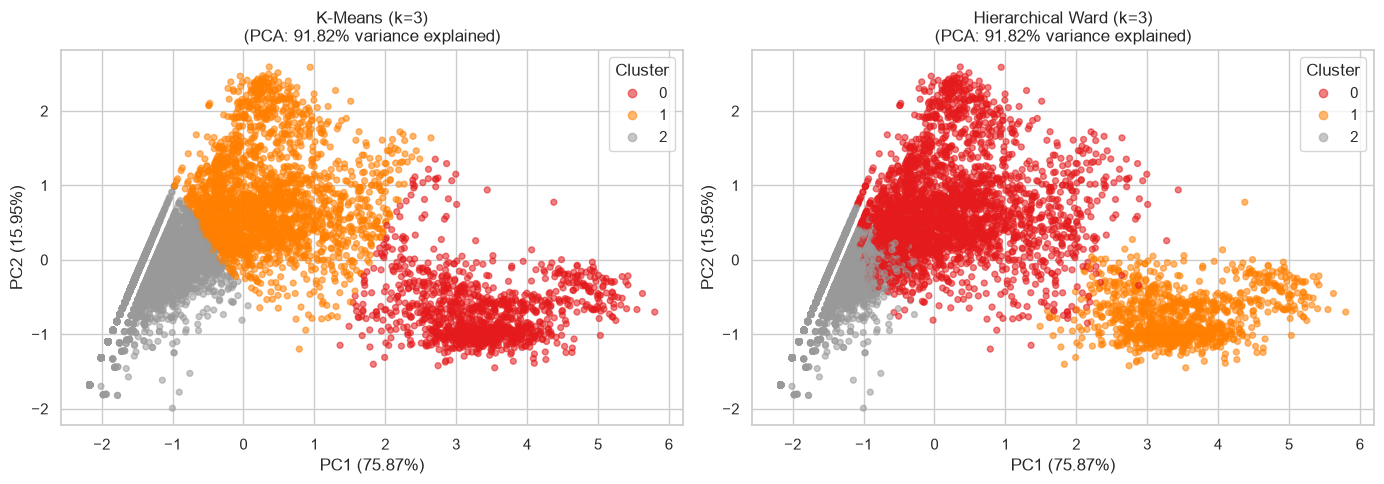

In [26]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_log_scaled)
var_ratio = pca.explained_variance_ratio_ * 100
print(f"Explained Variance Ratio: PC1={var_ratio[0]:.2f}%, PC2={var_ratio[1]:.2f}%, Total={var_ratio.sum():.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, labels, title in [
    (axes[0], km_labels, "K-Means (k=3)"),
    (axes[1], hc_labels, "Hierarchical Ward (k=3)")
]:
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="Set1", alpha=0.55, s=18)
    ax.set_title(f"{title}\n(PCA: {var_ratio.sum():.2f}% variance explained)")
    ax.set_xlabel(f"PC1 ({var_ratio[0]:.2f}%)")
    ax.set_ylabel(f"PC2 ({var_ratio[1]:.2f}%)")
    ax.legend(*scatter.legend_elements(), title="Cluster")

plt.tight_layout()
plt.show()

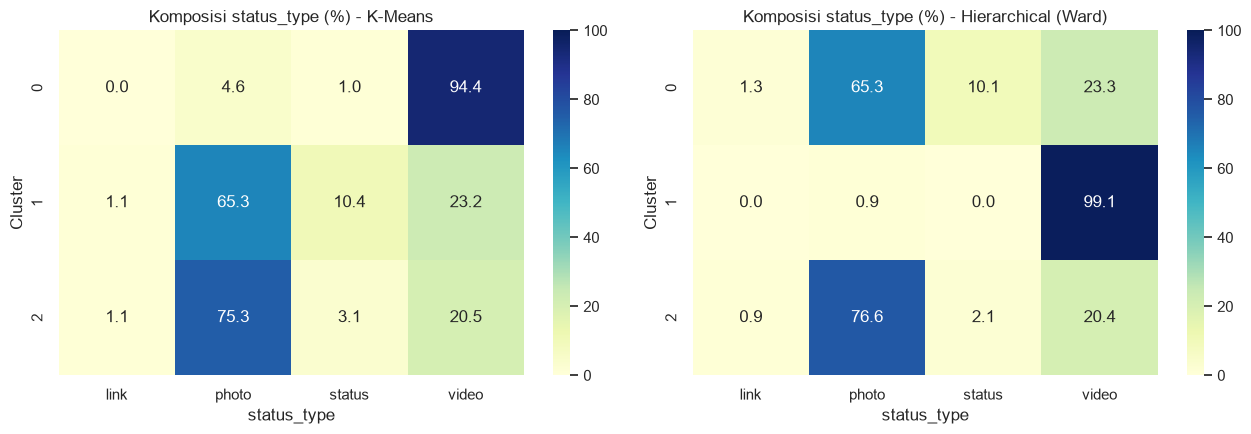

In [27]:
ct_km = pd.crosstab(km_labels, meta_df["status_type"], normalize="index") * 100
ct_hc = pd.crosstab(hc_labels, meta_df["status_type"], normalize="index") * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(ct_km, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[0], vmin=0, vmax=100)
axes[0].set_title("Komposisi status_type (%) - K-Means")
axes[0].set_ylabel("Cluster")

sns.heatmap(ct_hc, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[1], vmin=0, vmax=100)
axes[1].set_title("Komposisi status_type (%) - Hierarchical (Ward)")
axes[1].set_ylabel("Cluster")

plt.tight_layout()
plt.show()

# 6. Analisis

### Analisis Hasil Eksperimen

1. **Pengaruh Transformasi Log (`log1p`) dan Feature Scaling pada K-Means (Bagian 3.1):**
   - Pada data mentah (`X_raw`), varians fitur sangat timpang: `num_comments` memiliki varians **797.310,07** dan `num_likes` **193.268,44**, jauh di atas `num_shares` (17.443,17) dan `num_emojis` (2.299,57). Akibatnya, perhitungan jarak Euclidean pada K-Means didominasi oleh `num_comments` dan outlier viral, menghasilkan cluster yang sangat timpang (`{0: 6392, 1: 137, 2: 467}`) dengan Silhouette Score rendah (**0,2731**).
   - Penerapan `StandardScaler` saja (`X_raw_scaled`) belum menyelesaikan masalah karena distribusi fitur tetap sangat miring ke kanan (*skewness* `num_comments` = 9,03; `num_shares` = 7,10; `num_likes` = 3,92). Outlier ekstrem masih menarik centroid sehingga menghasilkan satu cluster raksasa (`{0: 373, 1: 6277, 2: 346}`) dengan Silhouette Score **0,2533**.
   - Kombinasi **`log1p` + `StandardScaler` (`X_log_scaled`)** menekan skewness dan pengaruh outlier ekstrem sekaligus menyetarakan skala seluruh fitur (`mean = 0`, `std ≈ 1`). Hasilnya, terbentuk tiga cluster yang jauh lebih seimbang (`{0: 1131, 1: 2258, 2: 3607}`) dan Silhouette Score melonjak ke **0,4638**.

2. **Penanganan Fitur Redundan dan Sparse:**
   - Kolom `Column1`–`Column4` dihapus karena seluruhnya kosong (7.050 missing value), serta 54 baris duplikat (berdasarkan seluruh kolom selain `status_id`) dihapus sehingga tersisa 6.996 baris unik.
   - `num_reactions` dibuang karena merupakan penjumlahan dari `num_likes` dan reaksi emoji (`selisih maksimum = 4`), sehingga bersifat redundan.
   - Lima kolom reaksi emoji (`num_loves`, `num_wows`, `num_hahas`, `num_sads`, `num_angrys`) memiliki 60%–94% nilai nol dan baru aktif sejak 2016. Menggabungkannya menjadi `num_emojis` mengurangi sparsity dan menjaga kontribusi sinyal reaksi emosional tetap seimbang.

3. **Penentuan Jumlah Cluster Optimal (Elbow vs Silhouette):**
   - **Elbow Method** menunjukkan siku yang tegas pada **`k = 3`** (penurunan *inertia* sebesar 4.807,06 dari `k = 2` ke `k = 3`, lalu turun drastis menjadi 1.101,59 pada `k = 4`).
   - **Silhouette Score** mencapai puncak pada `k = 2` (0,5899) dan berada di posisi kedua terbaik pada `k = 3` (0,4638), lalu turun ke 0,3372 pada `k = 4`.
   - Keduanya sedikit berbeda karena `k = 2` hanya memisahkan postingan ber-engagement rendah dan tinggi secara kasar. Dengan mempertimbangkan siku Elbow yang jelas dan kebutuhan segmentasi yang lebih bermakna, **`k = 3`** dipilih sebagai jumlah cluster optimal.

4. **Perbandingan Metode Linkage pada Hierarchical Clustering:**
   - **`ward`** adalah linkage terbaik karena meminimalkan peningkatan varians intra-cluster (*within-cluster variance*), menghasilkan 3 cluster yang seimbang (`{0: 2922, 1: 1040, 2: 3034}`) dengan Silhouette Score **0,4201** dan struktur dendrogram yang jelas saat dipotong di ketinggian ~75.
   - **`single` linkage** membentuk satu cluster dominan berisi 6.994 titik dan dua cluster berisi masing-masing 1 titik (*chaining effect*). **`average` linkage** juga terdorong oleh outlier dengan memisahkan 35 titik ekstrem ke satu cluster kecil. **`complete` linkage** memberikan Silhouette Score terendah (0,1163).

5. **Perbandingan K-Means vs Hierarchical Clustering (Ward):**
   - Pada seluruh metrik internal, **K-Means (`k=3`)** sedikit mengungguli **Hierarchical Ward (`k=3`)**:
     - Silhouette Score: **0,4638** vs **0,4201** (lebih tinggi lebih baik)
     - Davies-Bouldin Index: **0,8302** vs **0,8329** (lebih rendah lebih baik)
     - Calinski-Harabasz Score: **10.935,46** vs **9.959,19** (lebih tinggi lebih baik)
   - Visualisasi PCA 2D (menjelaskan **91,82%** varians total: PC1 = 75,87%, PC2 = 15,95%) menunjukkan kedua metode menghasilkan batas partisi yang sangat mirip, hanya sedikit berbeda pada area transisi antara cluster engagement rendah dan menengah. Hal ini wajar karena K-Means dan Ward sama-sama mengoptimalkan kriteria berbasis varians/jarak Euclidean (*sum of squared errors*), namun K-Means melakukan penugasan ulang iteratif (*global refinement*) sedangkan Hierarchical bersifat *greedy* (penggabungan bertahap yang tidak dapat dibatalkan).

6. **Karakteristik Tiap Cluster & Penamaan:**
   - **Cluster 0 K-Means (1.131 posting) / Cluster 1 Ward (1.040 posting) — *"Live Video Viral / High-Interaction Sellers"*:**
     Didominasi sangat kuat oleh `video` (**94,4%** pada K-Means; **99,1%** pada Ward). Memiliki median komentar tertinggi (722 pada K-Means; 815,5 pada Ward), median share tertinggi (178 vs 193,5), serta median emoji tertinggi (57 vs 60,5). Ini merepresentasikan sesi *Facebook Live* penjualan yang memicu diskusi tanya-jawab aktif dari pembeli.
   - **Cluster 1 K-Means (2.258 posting) / Cluster 0 Ward (2.922 posting) — *"Popular Photo & Passive-Like Posts"*:**
     Didominasi `photo` (65,3% pada kedua metode), diikuti `video` (~23,2%) dan `status` (~10,1%–10,4%). Memiliki median `num_likes` tinggi (206 pada K-Means; 150 pada Ward), tetapi interaksi komentar (median 9–11), share (median 1), dan emoji (median 1–2) relatif moderat hingga rendah.
   - **Cluster 2 K-Means (3.607 posting) / Cluster 2 Ward (3.034 posting) — *"Low-Engagement / Quiet Posts"*:**
     Mayoritas berupa `photo` (75,3% K-Means; 76,6% Ward) dan `video` (20,4%–20,5%). Memiliki median `num_likes` rendah (18 K-Means; 14 Ward) serta median `num_comments`, `num_shares`, dan `num_emojis` bernilai **0**.

7. **Kelebihan dan Kekurangan Masing-Masing Metode:**
   - **K-Means:** Cepat secara komputasi ($O(n \cdot k \cdot d \cdot t)$), efisien memori, dan mampu memperbaiki batas cluster secara iteratif; kekurangannya harus menentukan `k` di awal, sensitif terhadap inisialisasi (diatasi dengan `n_init=10` dan `random_state`), serta cenderung membentuk cluster berbentuk bulat (*spherical*).
   - **Hierarchical Clustering (Agglomerative):** Tidak mewajibkan penentuan `k` di awal karena menghasilkan dendrogram hierarkis yang mudah dieksplorasi pada berbagai tingkat pemotongan; kekurangannya membutuhkan waktu dan memori lebih besar ($O(n^2)$ hingga $O(n^3)$) untuk dataset berskala besar, serta penggabungan yang sudah terjadi bersifat permanen (*greedy*).

# 7. Kesimpulan dan Saran

### Kesimpulan
1. Dataset `Live.csv` (7.050 baris, setelah dibersihkan menjadi 6.996 baris unik) memiliki fitur engagement yang sangat miring ke kanan (*right-skewed*) dan mengandung outlier viral serta fitur emoji yang *sparse*.
2. **Preprocessing** dengan menghapus fitur redundan (`num_reactions`), menggabungkan reaksi emoji menjadi `num_emojis`, menerapkan transformasi `log1p`, dan melakukan `StandardScaler` terbukti krusial—meningkatkan Silhouette Score K-Means (`k=3`) dari **0,2731** (data mentah) menjadi **0,4638**.
3. Baik **K-Means (`k=3`)** maupun **Hierarchical Clustering (`ward`, `k=3`)** berhasil mengidentifikasi tiga segmen postingan yang konsisten dan bermakna secara bisnis: (1) *High-Interaction Live Videos* (94%–99% video dengan komentar dan share sangat tinggi), (2) *Popular Photo & Passive-Like Posts* (like tinggi namun komentar/share rendah), dan (3) *Low-Engagement Posts*.
4. Secara kuantitatif, **K-Means** memberikan hasil sedikit lebih baik daripada Hierarchical Ward pada seluruh metrik evaluasi internal (Silhouette **0,4638** vs 0,4201; Davies-Bouldin **0,8302** vs 0,8329; Calinski-Harabasz **10.935,46** vs 9.959,19).

### Saran
1. **Analisis terpisah berdasarkan periode waktu (sebelum dan sesudah 2016):** Karena fitur reaksi emoji baru tersedia mulai tahun 2016, pemodelan terpisah untuk periode 2012–2015 dan 2016–2018 dapat menghindari bias akibat nol struktural (*structural zeros*) pada fitur emoji.
2. **Eksplorasi fitur waktu posting:** Menambahkan fitur hasil ekstraksi `status_published` seperti jam posting, hari dalam seminggu, atau akhir pekan vs hari kerja untuk melihat pola waktu yang memicu *live engagement* tertinggi.
3. **Mencoba algoritma clustering berbasis densitas atau probabilistik:** Menggunakan **DBSCAN / HDBSCAN** untuk mendeteksi postingan viral sebagai outlier secara eksplisit, atau **Gaussian Mixture Model (GMM)** untuk menangkap bentuk cluster elips yang saling tumpang tindih.
4. **Rekomendasi bisnis bagi penjual:** Karena hampir seluruh postingan berinteraksi tinggi adalah `video` (live selling), penjual dapat memfokuskan strategi promosi interaktif (tanya-jawab komentar dan ajakan share) pada format video live, sementara postingan `photo` digunakan sebagai katalog pasif pendukung.